# 01 - Exploratory data analysis

In this notebook we take a first look at the data of the turbine (WTG 01) before we build any model.
We want to know how windy the site is, how the wind changes over the year and over the day, how often the turbine was not running
and how the power depends on the wind speed.

The results are used for the first slides of the presentation, and they explain some decisions in the later notebooks:
- the wind speed distribution shows on which part of the power curve the turbine spends most of its time. This decides how much a wind
  speed error affects the power (notebook 03),
- the seasonality is a first hint that one error margin for the whole year might not fit every month (notebook 04),
- the outages show why we have to clean the data before fitting the power curve (notebook 02).

Steps:
1. Load data
2. Summary statistics
3. Wind speed distribution
4. Seasonality
5. Outages and data gaps
6. Wind speed vs. power

In [1]:
# libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
import openpyxl

FILE = "Wind_Data_WTG_01_20250101.xlsx"
CUT_IN = 3.5        # m/s, read off the power curve in notebook 02
RATED_SPEED = 11.0  # m/s, above this the turbine runs at full power

# colors of the slide deck (taken from the title photo of the presentation)
DEEP = "#3d5687"        # deep sky: bin means, emphasis
BLUE = "#5b86bd"        # sky: wind
LIGHT_BLUE = "#9dbbe0"  # light sky: data points behind a curve
TEAL = "#6fa9b6"        # horizon teal: second series
ORANGE = "#e8673a"      # blade tip: power
GRAY = "#b9c3cd"        # light haze: context
DARK_GRAY = "#6e7f8f"   # dark haze: axes and context points
INK = "#24324a"         # text and lines

# the plots that are on the slides are saved here, at the size they have on the slide
FIGURE_DIR = "Presentation/figures"

# font of the slides: Aptos comes with PowerPoint, without PowerPoint we use Arial
APTOS_DIR = Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts")
for font_file in APTOS_DIR.glob("Aptos*.ttf"):
    font_manager.fontManager.addfont(str(font_file))
if (APTOS_DIR / "Aptos.ttf").exists():
    FONT = "Aptos"
else:
    FONT = "Arial"

plt.rcParams.update({
    "font.family": FONT,
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": DARK_GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6eaee",
    "grid.linewidth": 0.6,
    "xtick.color": DARK_GRAY,
    "ytick.color": DARK_GRAY,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
    "figure.dpi": 150,    # shows the small slide figures a bit larger in the notebook
    "savefig.dpi": 220,   # resolution of the saved slide figures
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": FONT + ":italic",
    "mathtext.cal": FONT,   # we use no cursive math; the default cursive font of the Mac gives a font warning
})

## 1. Load data

The file is the hourly SCADA export of the turbine from 1 Jan to 31 Dec 2025. Each row is one hour in local time (with daylight saving).
We only keep the columns we need and rename them to short snake_case names:

| Column in the file | Meaning | Name here |
|---|---|---|
| `WindSpeedAve.(m/s)` | mean wind speed in the hour (measured on the nacelle) | `v` |
| `WindSpeedMax.(m/s)` | strongest gust in the hour | `v_max` |
| `GeneratorOutput(kW)` | mean power in the hour | `p` |
| `MaintenanceStop Time(min)` | minutes of maintenance stop in the hour | `maint` |
| `WindDirection(16Dir)` | wind direction (16 sectors) | not used |
| `Gen. Out.Energy(kWh)` | energy counter | not used, has catch-up values after data gaps |

In [2]:
# load the excel file and keep the columns we need
raw = pd.read_excel(FILE)
df = raw.rename(columns={"Time": "time",
                         "WindSpeedAve.(m/s)": "v",
                         "WindSpeedMax.(m/s)": "v_max",
                         "GeneratorOutput(kW)": "p",
                         "MaintenanceStop Time(min)": "maint"})
df = df[["time", "v", "v_max", "p", "maint"]]

# the maintenance stop time is stored as text "hh:mm:ss", we convert it to minutes
df["maint"] = pd.to_timedelta(df["maint"].astype(str), errors="coerce").dt.total_seconds() / 60

# month and hour of the day for the seasonality plots
df["month"] = df["time"].dt.month
df["hour"] = df["time"].dt.hour

# status of each hour (is maintenance stop or not)
no_data = df["v"].isna() | df["p"].isna()
df["status"] = "running"
df.loc[(df["p"] <= 1) & (df["v"] > 4), "status"] = "unflagged stop"   # windy, but no power and no flag
df.loc[df["maint"] > 0, "status"] = "maintenance stop"
df.loc[no_data, "status"] = "no data"
df.head()

,time,v,v_max,p,maint,month,hour,status
0,2025-01-01 00:00:00,3.4,4.6,5.9,0.0,1,0,running
1,2025-01-01 01:00:00,3.5,4.5,5.4,0.0,1,1,running
2,2025-01-01 02:00:00,3.2,4.5,-1.2,0.0,1,2,running
3,2025-01-01 03:00:00,3.7,4.6,15.7,0.0,1,3,running
4,2025-01-01 04:00:00,3.4,4.3,5.1,0.0,1,4,running


## 2. Summary statistics

The rated power of the turbine is not in the file, so we estimate it from the data: we take the median power of the hours with
$v \ge 12$ m/s, where the turbine should run at full power. The capacity factor is the mean power divided by the rated power,
so the share of the maximum possible energy that the turbine actually produced.

In [3]:
# rated power = median power of the running hours with strong wind
running = df[df["status"] == "running"]
rated = running.loc[running["v"] >= 12, "p"].median()

# key numbers for the first slide
summary = {
    "hours in file": f"{len(df)}",
    "hours with data": f"{(~no_data).sum()}",
    "mean / median wind speed": f"{df['v'].mean():.1f} / {df['v'].median():.1f} m/s",
    "max hourly wind speed / max gust": f"{df['v'].max():.1f} / {df['v_max'].max():.1f} m/s",
    "rated power (median at v >= 12 m/s)": f"{rated:.0f} kW",
    "mean power": f"{df['p'].mean():.0f} kW",
    "energy produced (hours with data)": f"{df['p'].sum() / 1000:.0f} MWh",
    "hours at >= 95 % of rated power": f"{(df['p'] >= 0.95 * rated).mean():.1%}",
    "hours with P <= 1 kW": f"{(df['p'] <= 1).mean():.1%}",
}
pd.Series(summary, name="value").to_frame()

,value
hours in file,8761
hours with data,8706
mean / median wind speed,5.2 / 4.7 m/s
max hourly wind speed / max gust,14.9 / 20.1 m/s
rated power (median at v >= 12 m/s),1034 kW
mean power,242 kW
energy produced (hours with data),2103 MWh
hours at >= 95 % of rated power,5.1%
hours with P <= 1 kW,23.0%


## 3. Wind speed distribution

The power curve has three parts. Below cut-in (about 3.5 m/s) the turbine produces almost nothing, between cut-in and rated speed
(about 11 m/s) the power rises steeply, and above rated speed it stays at full power.
We count how many hours fall into each part, because an error in the wind speed only changes the power on the steep part.

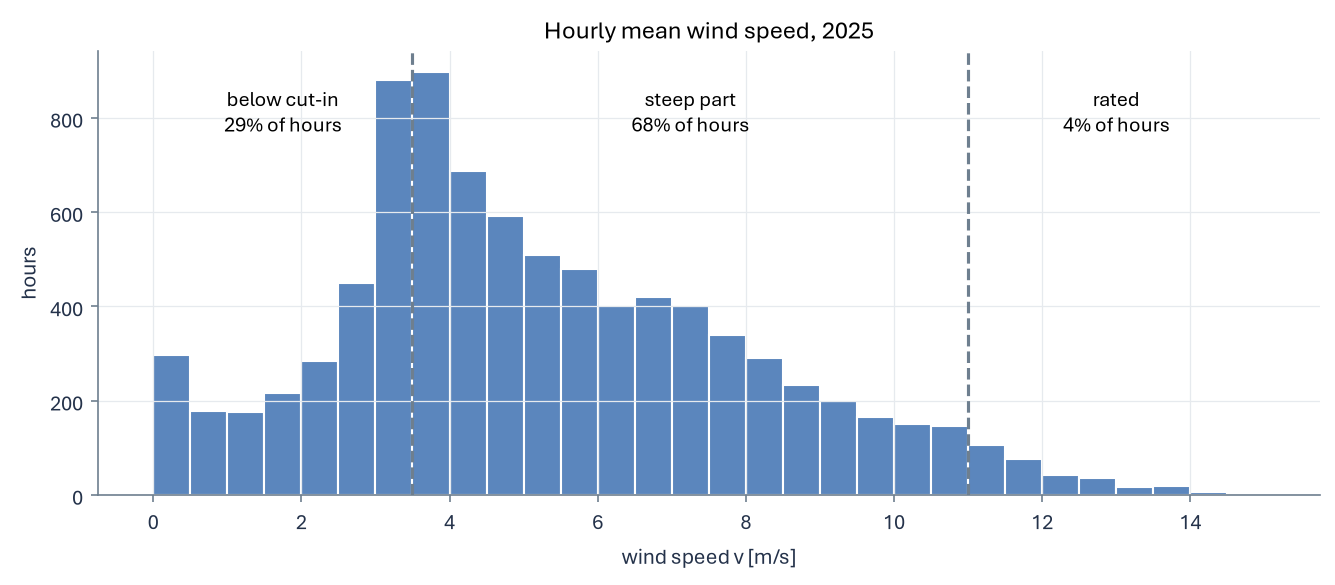

In [4]:
# share of hours in each part of the power curve
v = df["v"].dropna()
share_below = (v < CUT_IN).mean()
share_steep = ((v >= CUT_IN) & (v < RATED_SPEED)).mean()
share_rated = (v >= RATED_SPEED).mean()

# histogram with the borders between the three parts
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=np.arange(0, 15.5, 0.5), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(CUT_IN, color=DARK_GRAY, ls="--", lw=1.5)
ax.axvline(RATED_SPEED, color=DARK_GRAY, ls="--", lw=1.5)
y_max = ax.get_ylim()[1]
ax.text(CUT_IN / 2, y_max * 0.92, f"below cut-in\n{share_below:.0%} of hours", ha="center", va="top")
ax.text((CUT_IN + RATED_SPEED) / 2, y_max * 0.92, f"steep part\n{share_steep:.0%} of hours", ha="center", va="top")
ax.text(13, y_max * 0.92, f"rated\n{share_rated:.0%} of hours", ha="center", va="top")
ax.set_title("Hourly mean wind speed, 2025")
ax.set_xlabel("wind speed v [m/s]")
ax.set_ylabel("hours")
plt.tight_layout()
plt.show()

## 4. Seasonality

First the mean wind speed and the produced energy per month. Then a heatmap of the mean wind speed per month and hour of the day,
to see if the wind also has a daily pattern.

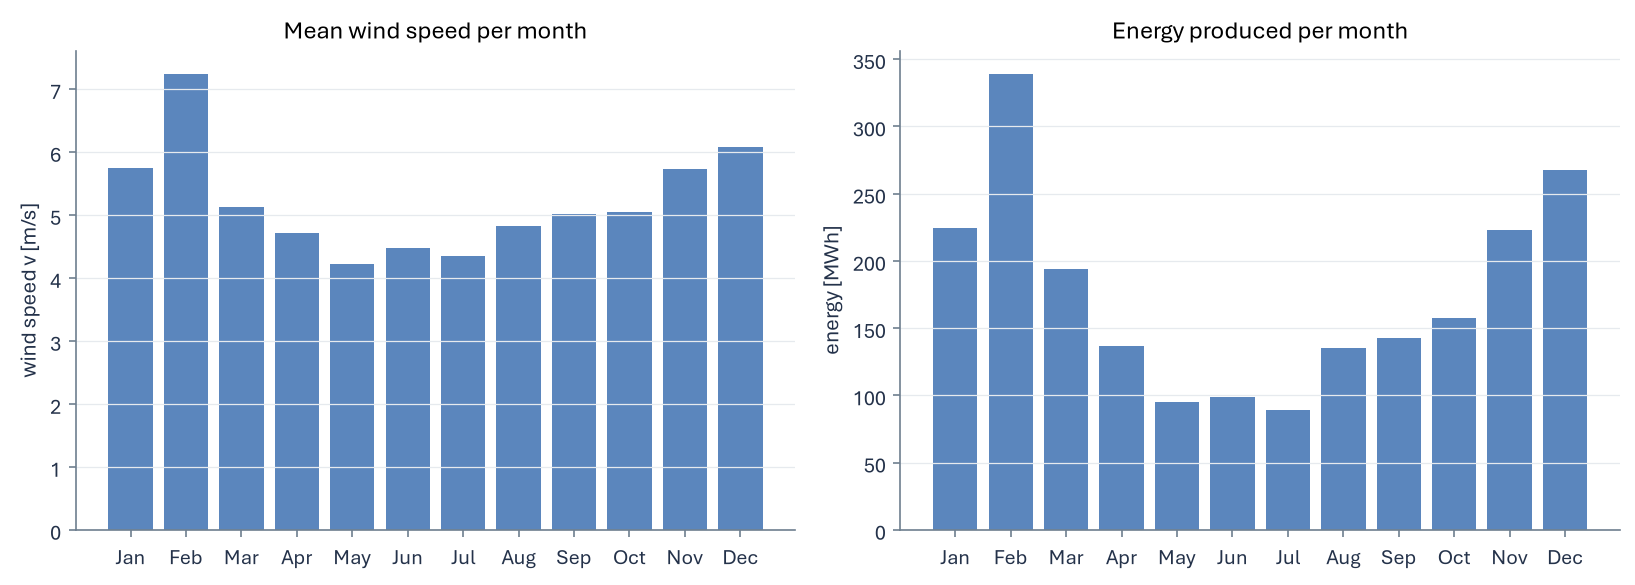

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
v,5.75,7.24,5.12,4.72,4.23,4.47,4.34,4.83,5.02,5.04,5.73,6.07
energy,224.34,339.19,193.81,136.57,94.80,98.98,89.19,135.09,143.03,157.43,223.11,267.86
capacity_factor,0.29,0.49,0.25,0.18,0.13,0.14,0.12,0.18,0.19,0.20,0.30,0.35


In [5]:
# mean wind speed and energy per month (sum of the hourly mean power in kW = kWh, divided by 1000 for MWh)
monthly = df.groupby("month").agg(v=("v", "mean"), energy=("p", "sum"))
monthly["energy"] = monthly["energy"] / 1000
month_names = pd.to_datetime(monthly.index, format="%m").strftime("%b")

# two bar charts next to each other (different units, so two separate plots)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(month_names, monthly["v"], color=BLUE, width=0.8)
ax1.set(title="Mean wind speed per month", ylabel="wind speed v [m/s]")
ax2.bar(month_names, monthly["energy"], color=BLUE, width=0.8)
ax2.set(title="Energy produced per month", ylabel="energy [MWh]")
ax1.grid(axis="x", visible=False)
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# table with the monthly values and the capacity factor per month
monthly["capacity_factor"] = df.groupby("month")["p"].mean() / rated
monthly.index = month_names
monthly.round(2).T

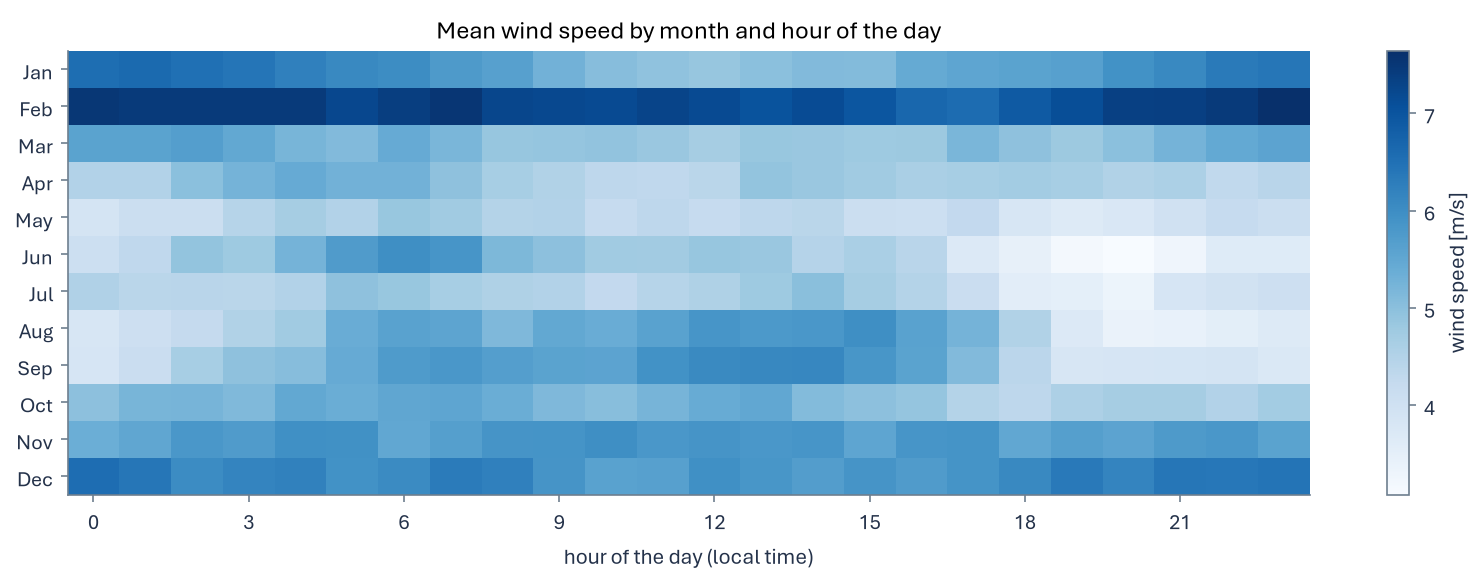

In [6]:
# heatmap: mean wind speed per month (rows) and hour of the day (columns)
heat = df.pivot_table(index="month", columns="hour", values="v", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat, aspect="auto", cmap="Blues", origin="upper")
ax.set_yticks(range(12), month_names)
ax.set_xticks(range(0, 24, 3))
ax.set(title="Mean wind speed by month and hour of the day", xlabel="hour of the day (local time)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="wind speed [m/s]")
plt.tight_layout()
plt.show()

## 5. Outages and data gaps

We look at three kinds of hours in which the turbine did not run normally:
- **no data:** the row is empty,
- **maintenance stop:** the turbine logged a maintenance stop,
- **unflagged stop:** windy ($v > 4$ m/s) but no power ($P \le 1$ kW), and there is no flag in the file. So the turbine was stopped
  and we don't know why.

These hours don't show how the turbine turns wind into power and would pull the power curve down, so we remove them in notebook 02.
For Georgi they still matter, because every outage is lost production.

status
running             8570
maintenance stop      80
unflagged stop        56
no data               55 



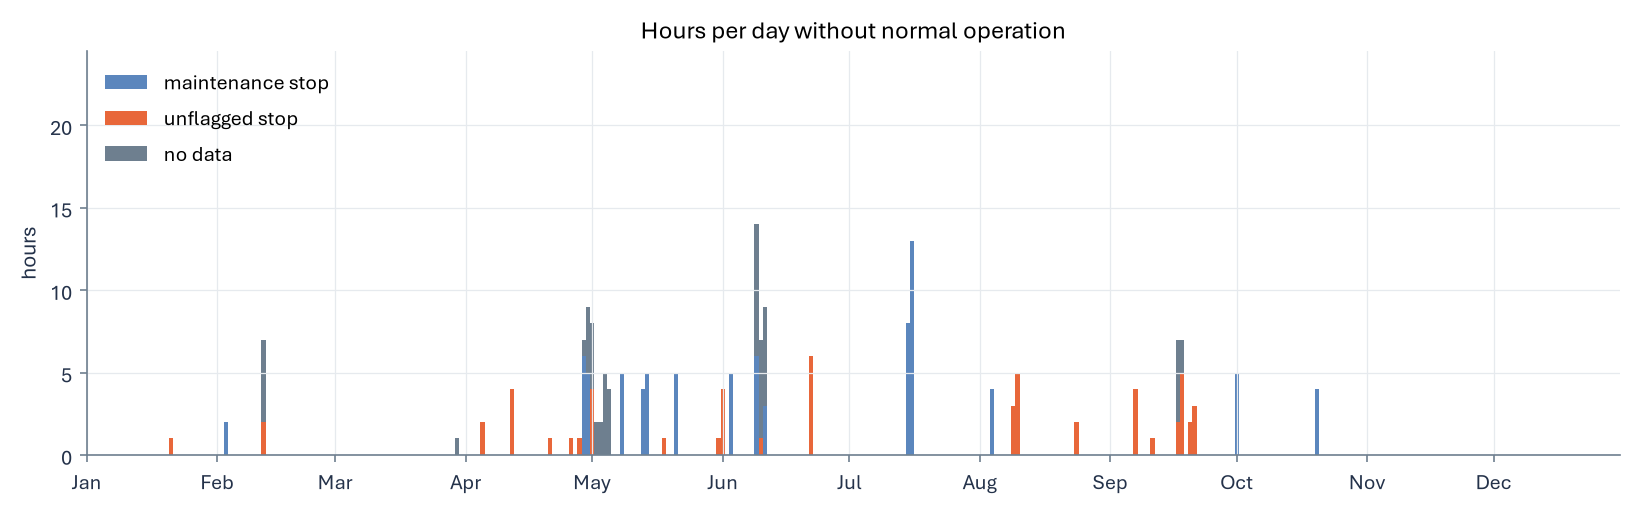

In [7]:
order = ["maintenance stop", "unflagged stop", "no data"]
colors = {"maintenance stop": BLUE, "unflagged stop": ORANGE, "no data": DARK_GRAY}

# number of hours per status
counts = df["status"].value_counts().reindex(["running"] + order)
print(counts.to_string(), "\n")

# hours per day and status (0 for days without problems)
days = pd.date_range(df["time"].min().normalize(), df["time"].max().normalize(), freq="D")
problems = df[df["status"] != "running"]
lost = problems.groupby([problems["time"].dt.normalize(), "status"]).size()
lost = lost.unstack(fill_value=0)
lost = lost.reindex(index=days, columns=order, fill_value=0)

# stacked bar chart, one bar per day
fig, ax = plt.subplots(figsize=(11, 3.5))
bottom = np.zeros(len(lost))
for status in order:
    ax.bar(lost.index, lost[status], bottom=bottom, width=1, color=colors[status], label=status)
    bottom = bottom + lost[status].to_numpy()
ax.set(title="Hours per day without normal operation", ylabel="hours", ylim=(0, 24.5), xlim=(days[0], days[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. Wind speed vs. power

If we plot the power against the wind speed for every hour of the year, we get the S-shaped power curve. The hours with stops are marked
in color. In notebook 02 we fit one curve $P(v)$ through the normal hours.

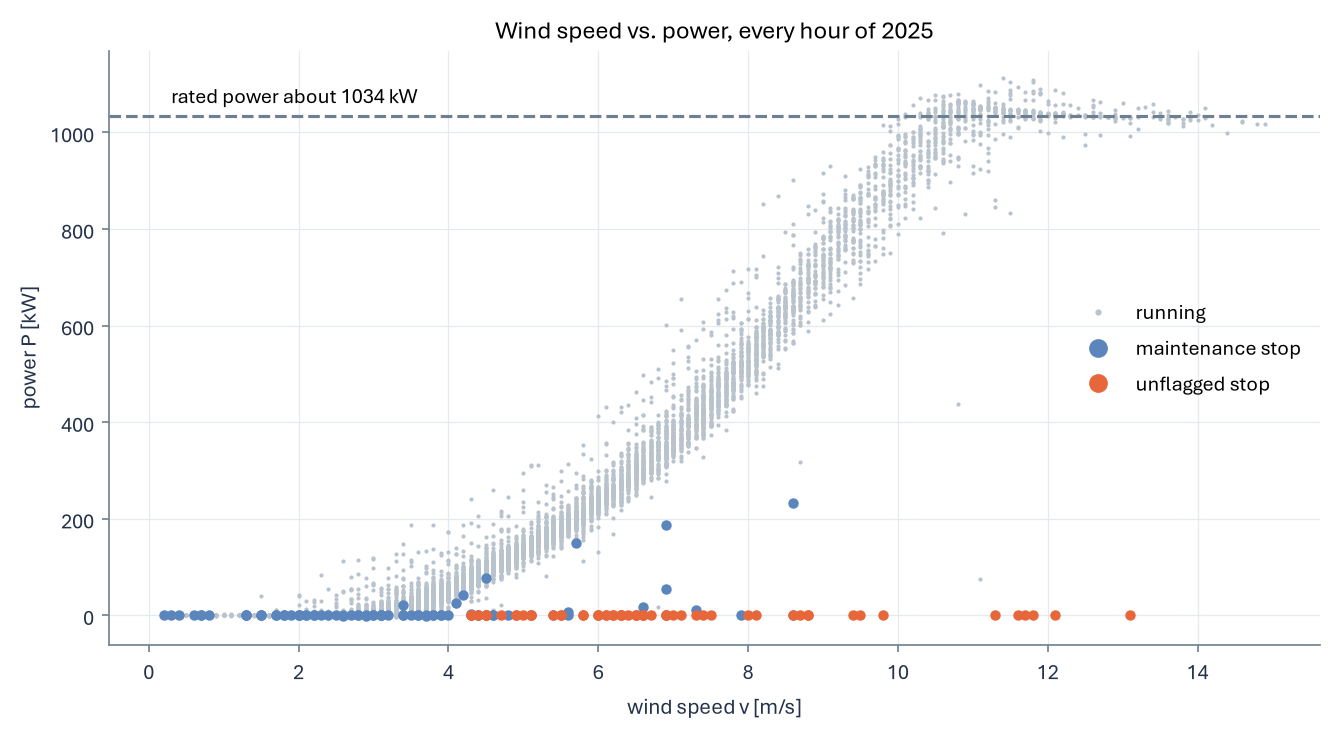

In [8]:
# every hour of the year: running hours in gray, stops in color
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(running["v"], running["p"], ".", ms=2, color=GRAY, label="running")
for status in ["maintenance stop", "unflagged stop"]:
    stopped = df[df["status"] == status]
    ax.plot(stopped["v"], stopped["p"], "o", ms=4, color=colors[status], label=status)
ax.axhline(rated, color=DARK_GRAY, ls="--", lw=1.5)
ax.text(0.3, rated + 15, f"rated power about {rated:.0f} kW", va="bottom")
ax.set(title="Wind speed vs. power, every hour of 2025", xlabel="wind speed v [m/s]", ylabel="power P [kW]")
ax.legend(markerscale=2, loc="center right")
plt.tight_layout()
plt.show()

## Takeaways

- The turbine has a rated power of about 1034 kW. In 2025 the mean wind was 5.2 m/s and the mean power 242 kW, so the capacity factor
  is about 23 % (2103 MWh produced). It runs at (almost) full power in only 5 % of the hours and produces nothing in 23 %.
- 68 % of the hours are on the steep part of the power curve (3.5-11 m/s) and only 4 % at rated speed. So most of the time an error in
  the wind speed directly changes the power. This is why we look at the error propagation in notebook 03.
- The seasonality is strong: February was the windiest month (7.2 m/s, 339 MWh, capacity factor 49 %), July produced only 89 MWh (12 %).
  The three winter months produced about 2.6 times as much energy as the three summer months. In winter the wind hardly changes over
  the day, in summer the evenings are calm. So one error margin for the whole year might not fit every season.
- Outages are rare: 191 hours (2.2 %), 80 h maintenance stops, 56 h unflagged stops and 55 h without data, most of them in May and June.
  The unflagged stops can only be found in the data (windy, but no power), so notebook 02 removes them before fitting the curve.
- Power against wind speed gives a clear S-shaped curve with little scatter, plus the stops on the x-axis.

Next: notebook 02 cleans the data and fits the power curve.